In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline


In [2]:
df = pd.read_csv("3-customersatisfaction.csv")

In [3]:
df.describe()

,Unnamed: 0,Customer Satisfaction,Incentive
count,100.000000,100.000000,100.000000
mean,49.500000,-0.005427,3.445220
std,29.011492,1.721792,2.911818
min,0.000000,-2.992863,-1.068081
25%,24.750000,-1.431357,1.471341
50%,49.500000,0.109167,2.748839
75%,74.250000,1.421119,4.739113
max,99.000000,2.986736,11.000056


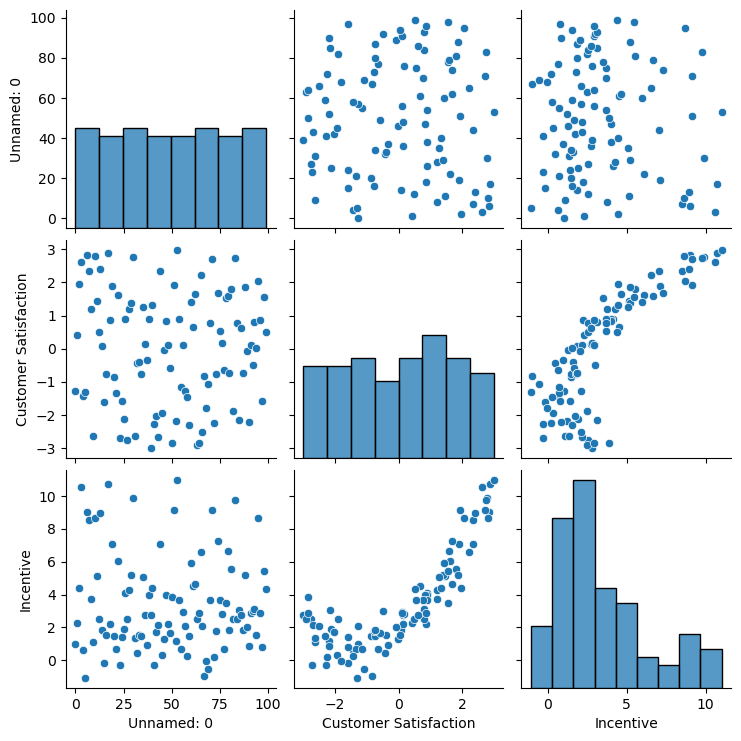

In [4]:
sns.pairplot(data=df)
plt.show()

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

In [6]:
df.drop("Unnamed: 0",axis=1, inplace=True)

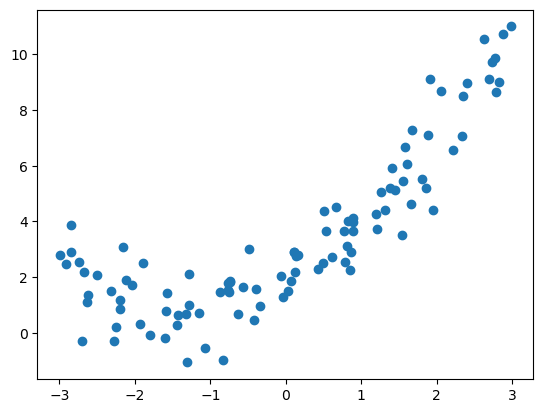

In [7]:
plt.scatter(x=df["Customer Satisfaction"], y=df["Incentive"])
plt.show()

In [8]:
# dependent, independent features

X=df[["Customer Satisfaction"]]
y=df["Incentive"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=15)

In [10]:
X_train["Customer Satisfaction"].value_counts()

Customer Satisfaction
 0.512504    1
 2.625838    1
-0.865714    1
-1.145369    1
 2.823460    1
            ..
 1.191020    1
-1.282447    1
-1.311432    1
 0.490521    1
-2.243889    1
Name: count, Length: 80, dtype: int64

In [11]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

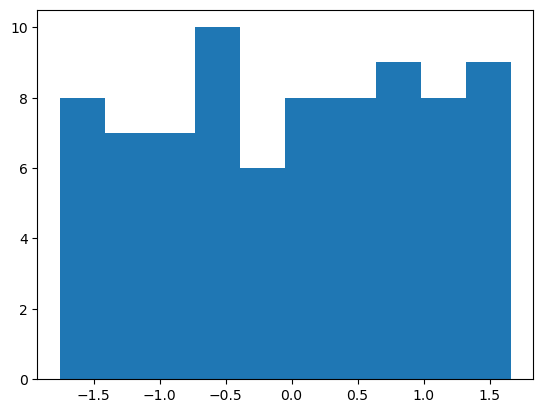

In [12]:
plt.hist(X_train)
plt.show()

In [13]:
regression = LinearRegression()

In [14]:
regression.fit(X_train, y_train)

LinearRegression()

In [15]:
y_pred = regression.predict(X_test)

In [16]:
y_pred

array([ 4.65663741,  3.71913877,  1.64121789,  6.29646523,  3.46766736,
        5.7580845 ,  4.692485  ,  3.61616231,  5.62448003,  0.13472702,
        4.47909659,  4.8130839 ,  1.58319087,  0.30515983,  5.27634309,
        0.41711005, -0.7385295 , -0.32653914,  3.55906887,  1.19798631])

In [17]:
score = r2_score(y_test, y_pred)
print("r2 score:", score)

r2 score: 0.2705652535622246


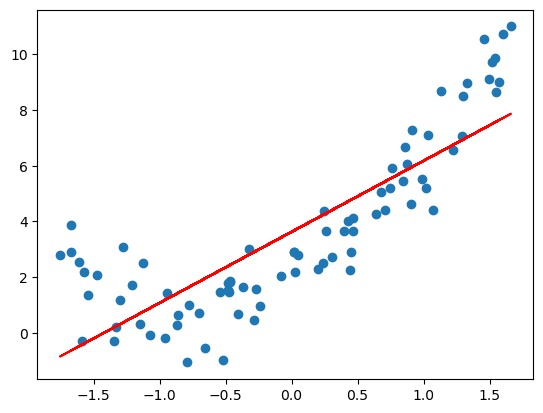

In [18]:
plt.scatter(X_train, y_train)
plt.plot(X_train, regression.predict(X_train), color="r")
plt.show()

In [19]:
poly = PolynomialFeatures(degree=2, include_bias=True)

In [20]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [21]:
regression = LinearRegression()

In [22]:
regression.fit(X_train_poly, y_train) # burada y_train neden polynomial değil?

LinearRegression()

In [23]:
y_pred = regression.predict(X_test_poly)
score = r2_score(y_test, y_pred)
print(score)

0.7685687698788557


In [24]:
regression.coef_

array([0.        , 2.63871762, 1.54959954])

In [25]:
regression.intercept_

np.float64(2.076676429793282)

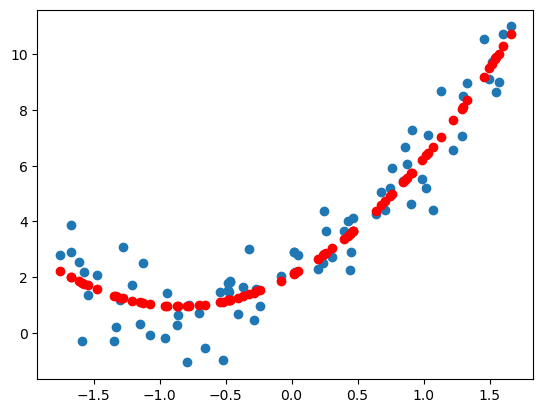

In [26]:
plt.scatter(X_train, y_train)
plt.scatter(X_train, regression.predict(X_train_poly), color="r")
plt.show()

In [27]:
new_df = pd.read_csv("3-newdatas.csv")

In [28]:
new_df.rename(columns={"0": "Customer Satisfaction"}, inplace=True)

In [29]:
new_df

,Customer Satisfaction
0,-3.000000
1,-2.969849
2,-2.939698
3,-2.909548
4,-2.879397
...,...
195,2.879397
196,2.909548
197,2.939698
198,2.969849


In [41]:
X_new= scaler.fit_transform(new_df)

In [42]:
X_new_poly = poly.transform(X_new)

In [44]:
y_new_pred = regression.predict(X_new_poly)

array([ 2.1316205 ,  2.08527648,  2.03986225,  1.99537781,  1.95182314,
        1.90919826,  1.86750316,  1.82673785,  1.78690232,  1.74799657,
        1.7100206 ,  1.67297442,  1.63685802,  1.6016714 ,  1.56741457,
        1.53408751,  1.50169025,  1.47022276,  1.43968506,  1.41007714,
        1.381399  ,  1.35365065,  1.32683208,  1.30094329,  1.27598428,
        1.25195506,  1.22885562,  1.20668597,  1.1854461 ,  1.16513601,
        1.1457557 ,  1.12730518,  1.10978443,  1.09319348,  1.0775323 ,
        1.06280091,  1.0489993 ,  1.03612747,  1.02418543,  1.01317317,
        1.00309069,  0.993938  ,  0.98571509,  0.97842196,  0.97205862,
        0.96662505,  0.96212127,  0.95854728,  0.95590306,  0.95418863,
        0.95340399,  0.95354912,  0.95462404,  0.95662874,  0.95956323,
        0.96342749,  0.96822154,  0.97394538,  0.98059899,  0.98818239,
        0.99669558,  1.00613854,  1.01651129,  1.02781382,  1.04004613,
        1.05320823,  1.06730011,  1.08232177,  1.09827322,  1.11

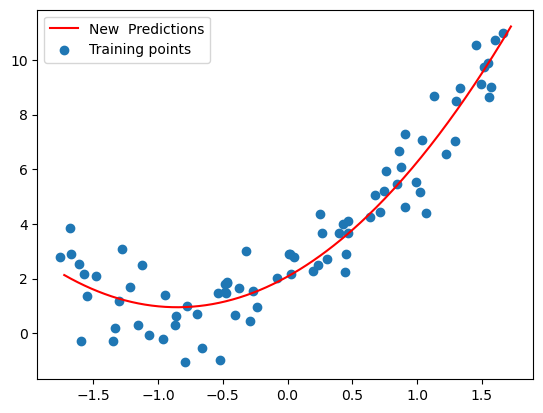

In [51]:
plt.plot(X_new, y_new_pred, label="New  Predictions", color="r")
plt.scatter(X_train, y_train, label="Training points")
plt.legend()
plt.show()

In [52]:
# pipeline (this is the crucial one)

In [92]:
def poly_regression(degree):
    poly_features = PolynomialFeatures(degree=degree)
    lin_reg = LinearRegression()
    scaler = StandardScaler()
    pipeline = Pipeline([
        ("standard_scaler", scaler),
        ("poly_features", poly_features),
        ("lin_reg", lin_reg),
    ])
    pipeline.fit(X_train, y_train) # yazdığım her şeyi bir kere "fit"liyorum. Her defasında uğraşmama gerek kalmıyor.
    score = pipeline.score(X_test, y_test) # Vermediğim 2 veri kalmıştı onları da böylece vermiş oluyorum.(?)

    # when introduced new datas to be predicted
    y_pred_new = pipeline.predict(X_new) # X_new had been transformed before.
    plt.plot(X_new, y_pred_new, color="r", label="New Predictions")
    plt.scatter(X_train, y_train, label="Training Points")
    plt.scatter(X_test, y_test, label="Test Points")
    plt.legend()
    plt.show()
    
    return score

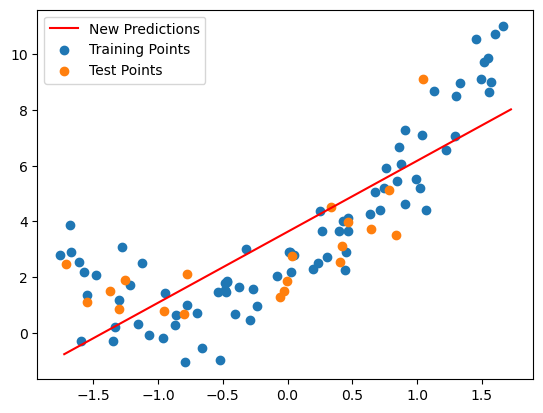

degree: 1	 0.2705652535622246


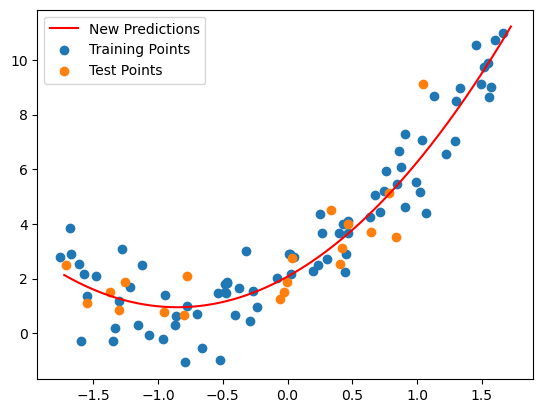

degree: 2	 0.7685687698788558


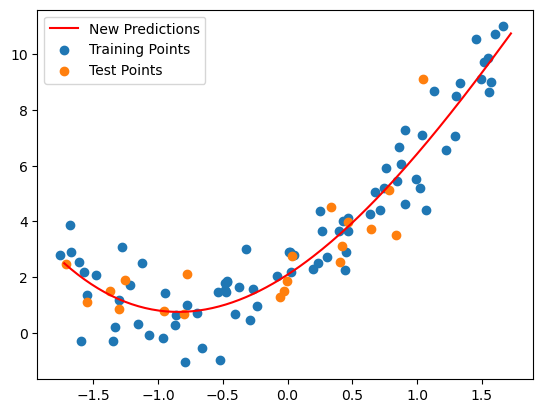

degree: 3	 0.757344362140105


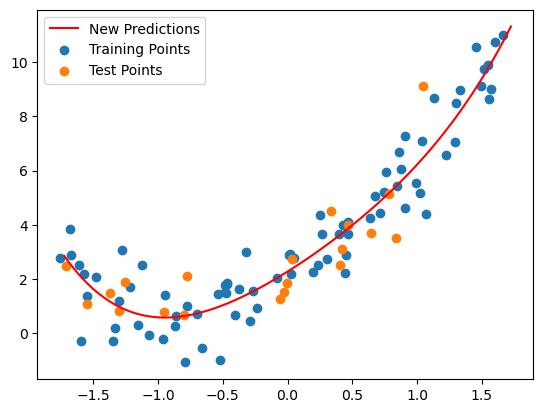

degree: 4	 0.7355034443260413


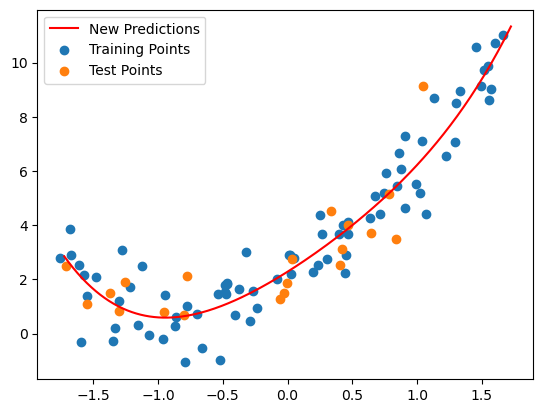

degree: 5	 0.7351244165095399


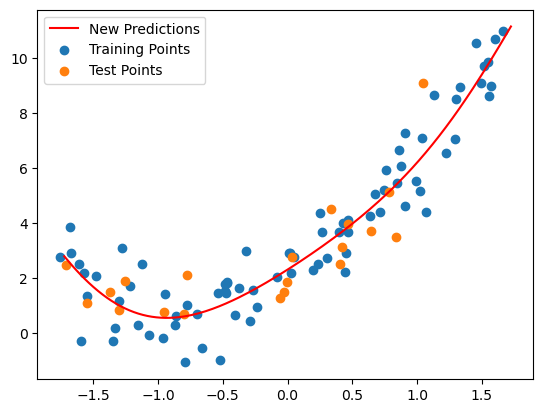

degree: 6	 0.7343590482133429


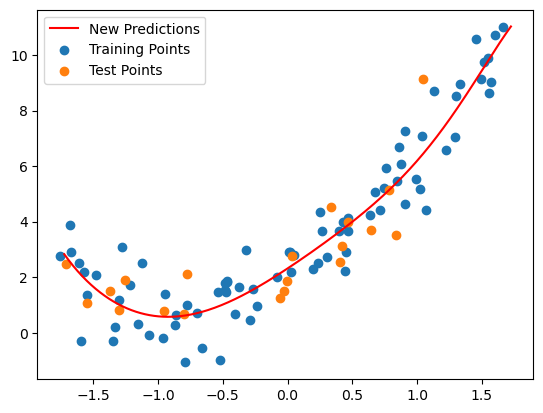

degree: 7	 0.7347819263549453


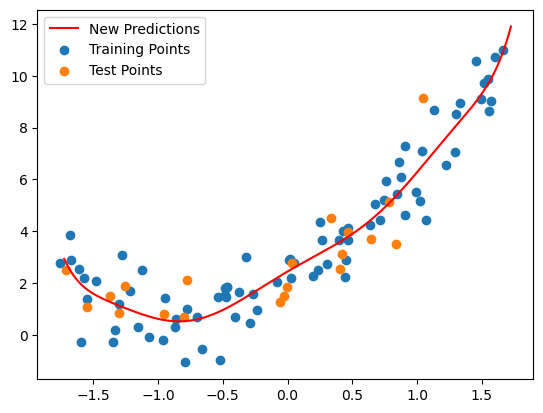

degree: 8	 0.7411422099998382


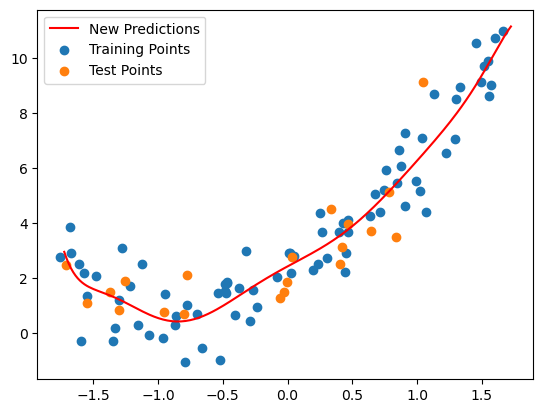

degree: 9	 0.7310763879815942


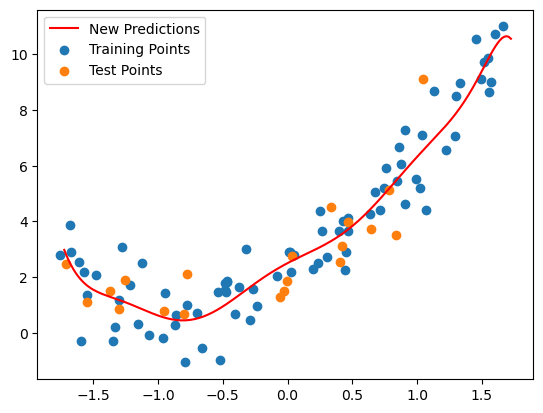

degree: 10	 0.7280578621232846


In [93]:
for degree in range(1,11):
    print("degree: {}\t".format(degree), poly_regression(degree))
    